# 03 — Rule-Based baseline
Baseline luật minh bạch để kiểm tra xem mô hình học máy có thực sự cải thiện so với logic thủ công hay không. Đây không phải mô hình AI được huấn luyện.

## 0. Chuẩn bị môi trường và tính tái lập
Dùng cùng dữ liệu, phép chia và seed với các notebook khác.

In [1]:
from pathlib import Path
import json, hashlib
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import platform, sklearn
import importlib
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score, roc_auc_score,
    average_precision_score, confusion_matrix, make_scorer)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.dummy import DummyClassifier
from securaai_ml.data import load_training_data
import securaai_ml.modeling as modeling_module
importlib.reload(modeling_module)  # tránh module cache cũ khi source vừa được cập nhật
from securaai_ml.modeling import (candidate_factories, decision_scores, parameter_grids,
    teaching_candidate_factories, teaching_parameter_grids)
from securaai_ml.schema import MODEL_FEATURES, TARGET_COLUMN, GROUP_COLUMN
from securaai_ml.train import temporal_train_validation_test

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data, audit = load_training_data(ROOT / 'data' / 'raw')
train, validation, test = temporal_train_validation_test(data)
X_train, y_train = train.loc[:, MODEL_FEATURES], train[TARGET_COLUMN]
X_validation, y_validation = validation.loc[:, MODEL_FEATURES], validation[TARGET_COLUMN]
groups = train[GROUP_COLUMN]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
audit

DatasetAudit(rows=102011, malicious=63792, benign=38219, groups=40, invalid_timestamps=0)

In [2]:
SEED=42
np.random.seed(SEED)
print('Rows:',len(data),'| Train:',len(train),'| Validation:',len(validation),'| Test:',len(test),'| Seed:',SEED)

Rows: 102011 | Train: 61277 | Validation: 20176 | Test: 20558 | Seed: 42


## 1. Xác thực dữ liệu và ý nghĩa nhãn
Nhãn là rule-derived ground truth; MITRE/Wazuh tag tạo nhãn không được dùng trong luật baseline.

In [3]:
display(pd.Series(audit.__dict__,name='value').to_frame())
assert audit.rows==len(data) and data[TARGET_COLUMN].nunique()==2
assert data[GROUP_COLUMN].ne('unknown-date').all()
print('Dataset checks passed')

,value
rows,102011
malicious,63792
benign,38219
groups,40
invalid_timestamps,0


Dataset checks passed


## 2. Chia Train/Validation/Test và dấu vân tay
Rule được thiết kế trước; Validation chỉ chọn ngưỡng, Test chỉ mở sau khi khóa.

In [4]:
split_table=pd.DataFrame([{'set':name,'rows':len(part),'attack_rate':float(part[TARGET_COLUMN].mean()),'dates':part[GROUP_COLUMN].nunique()} for name,part in [('Train',train),('Validation',validation),('Test',test)]])
display(split_table)
split_hash=hashlib.sha256(json.dumps({'train':sorted(train[GROUP_COLUMN].unique()),'validation':sorted(validation[GROUP_COLUMN].unique()),'test':sorted(test[GROUP_COLUMN].unique())},sort_keys=True).encode()).hexdigest()
print('Split hash:',split_hash[:16])

,set,rows,attack_rate,dates
0,Train,61277,0.669533,31
1,Validation,20176,0.548077,2
2,Test,20558,0.569462,7


Split hash: a94bf5446c1c1c5d


## 3. EDA chỉ trên Train
Quan sát phân bố nhãn và các feature mà rule sẽ sử dụng, không xem Test để sửa luật.

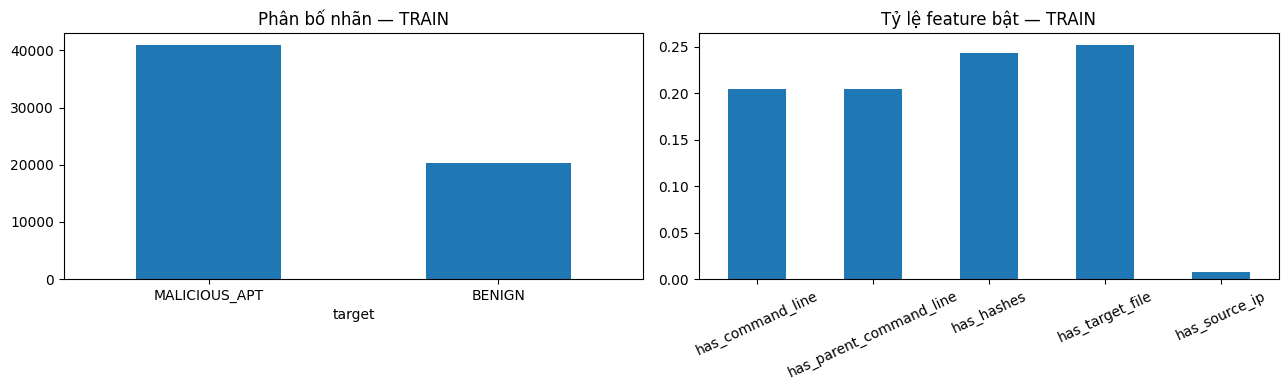

In [5]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
train[TARGET_COLUMN].map({0:'BENIGN',1:'MALICIOUS_APT'}).value_counts().plot.bar(ax=axes[0],rot=0,title='Phân bố nhãn — TRAIN')
train[['has_command_line','has_parent_command_line','has_hashes','has_target_file','has_source_ip']].mean().plot.bar(ax=axes[1],rot=25,title='Tỷ lệ feature bật — TRAIN')
plt.tight_layout(); plt.show()

## 4. Cơ chế luật và phạm vi triển khai
Mỗi dấu hiệu cộng một số điểm cố định. Luật dễ giải thích nhưng không tự học tương tác mới và không thay thế Wazuh rule.

In [6]:
rule_weights=pd.DataFrame([('has_command_line',2),('has_parent_command_line',1),('has_hashes',2),('has_target_file',1),('has_source_ip',1),('event_status failure/failed/denied',1)],columns=['condition','points'])
display(rule_weights)
def rule_score(frame):
    return (2*frame['has_command_line'] + frame['has_parent_command_line'] + 2*frame['has_hashes'] + frame['has_target_file'] + frame['has_source_ip'] + frame['event_status'].isin(['failure','failed','denied']).astype(int)).to_numpy(dtype=float)

,condition,points
0,has_command_line,2
1,has_parent_command_line,1
2,has_hashes,2
3,has_target_file,1
4,has_source_ip,1
5,event_status failure/failed/denied,1


## 5. Phân bố điểm luật trên Train
Nếu hai lớp chồng lấn nhiều, luật không thể phân tách tốt chỉ bằng một threshold.

target,BENIGN,MALICIOUS_APT
row_0,,
0.0,19898,10559
1.0,200,15728
2.0,37,2293
4.0,0,42
5.0,115,12405


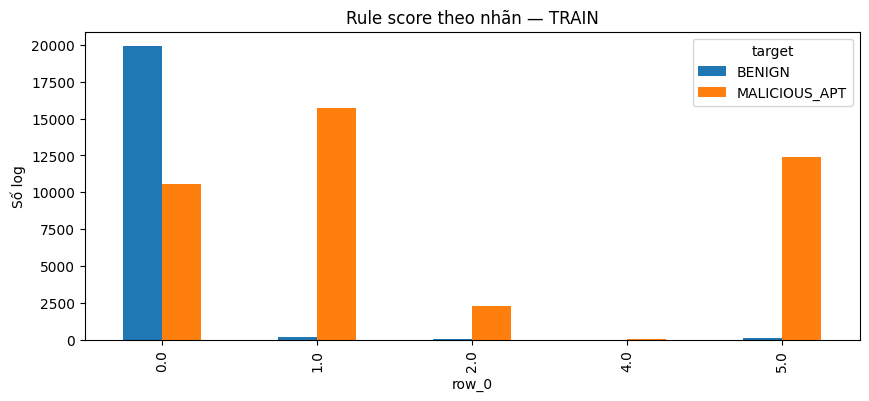

In [7]:
train_scores=rule_score(X_train)
score_distribution=pd.crosstab(train_scores,y_train).rename(columns={0:'BENIGN',1:'MALICIOUS_APT'})
display(score_distribution)
score_distribution.plot.bar(figsize=(10,4),title='Rule score theo nhãn — TRAIN'); plt.ylabel('Số log'); plt.show()

## 6. Dummy baseline
Rule-Based phải tốt hơn chiến lược đoán theo lớp phổ biến mới có giá trị.

In [8]:
dummy=DummyClassifier(strategy='prior').fit(X_train,y_train)
dummy_pred=dummy.predict(X_validation)
display(pd.Series({'accuracy':accuracy_score(y_validation,dummy_pred),'precision':precision_score(y_validation,dummy_pred,zero_division=0),'recall':recall_score(y_validation,dummy_pred,zero_division=0),'f1':f1_score(y_validation,dummy_pred,zero_division=0),'f2':fbeta_score(y_validation,dummy_pred,beta=2,zero_division=0)},name='Dummy — Validation').to_frame())

,Dummy — Validation
accuracy,0.548077
precision,0.548077
recall,1.000000
f1,0.708075
f2,0.858434


## 7. Chọn và khóa ngưỡng trên Validation
Thử toàn bộ ngưỡng nguyên có thể, chọn F2 cao nhất rồi không chỉnh lại sau khi xem Test.

,threshold,accuracy,precision,recall,f1,f2
0,1,0.959159,0.999902,0.925574,0.961304,0.939542
1,2,0.725515,0.999819,0.499277,0.665983,0.554830
2,3,0.692605,0.999794,0.439230,0.610329,0.494704
3,4,0.692655,1.000000,0.439230,0.610368,0.494714
4,5,0.692655,1.000000,0.439230,0.610368,0.494714
5,6,0.451923,0.000000,0.000000,0.000000,0.000000
6,7,0.451923,0.000000,0.000000,0.000000,0.000000
7,8,0.451923,0.000000,0.000000,0.000000,0.000000


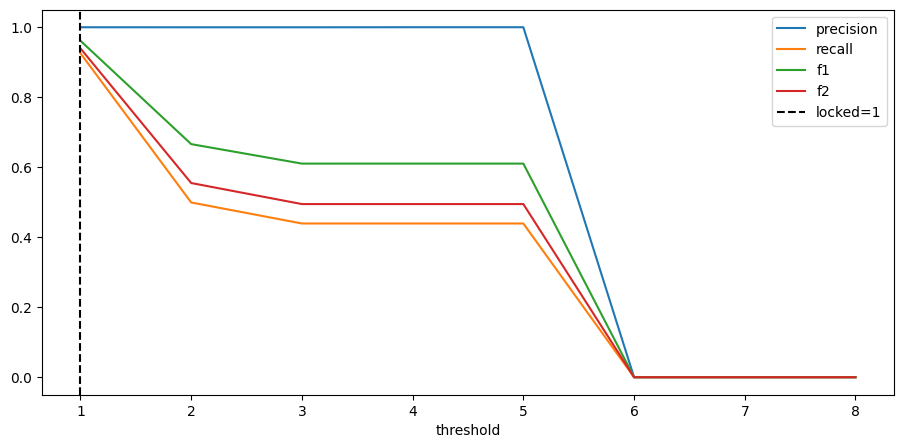

In [9]:
validation_score=rule_score(X_validation)
rows=[]
for threshold in range(1,9):
    pred=(validation_score>=threshold).astype(int)
    rows.append({'threshold':threshold,'accuracy':accuracy_score(y_validation,pred),'precision':precision_score(y_validation,pred,zero_division=0),'recall':recall_score(y_validation,pred,zero_division=0),'f1':f1_score(y_validation,pred,zero_division=0),'f2':fbeta_score(y_validation,pred,beta=2,zero_division=0)})
threshold_table=pd.DataFrame(rows); display(threshold_table)
chosen=threshold_table.sort_values(['f2','recall','precision'],ascending=False).iloc[0]
locked_threshold=int(chosen.threshold)
threshold_table.plot(x='threshold',y=['precision','recall','f1','f2'],figsize=(11,5)); plt.axvline(locked_threshold,color='black',ls='--',label=f'locked={locked_threshold}'); plt.legend(); plt.show()

## 8. Đánh giá trên Validation
Báo cáo Confusion Matrix, ROC và Precision–Recall tại ngưỡng đã khóa.

,VALIDATION
accuracy,0.959159
precision,0.999902
recall,0.925574
f1,0.961304
f2,0.939542
roc_auc,0.962730
average_precision,0.966313


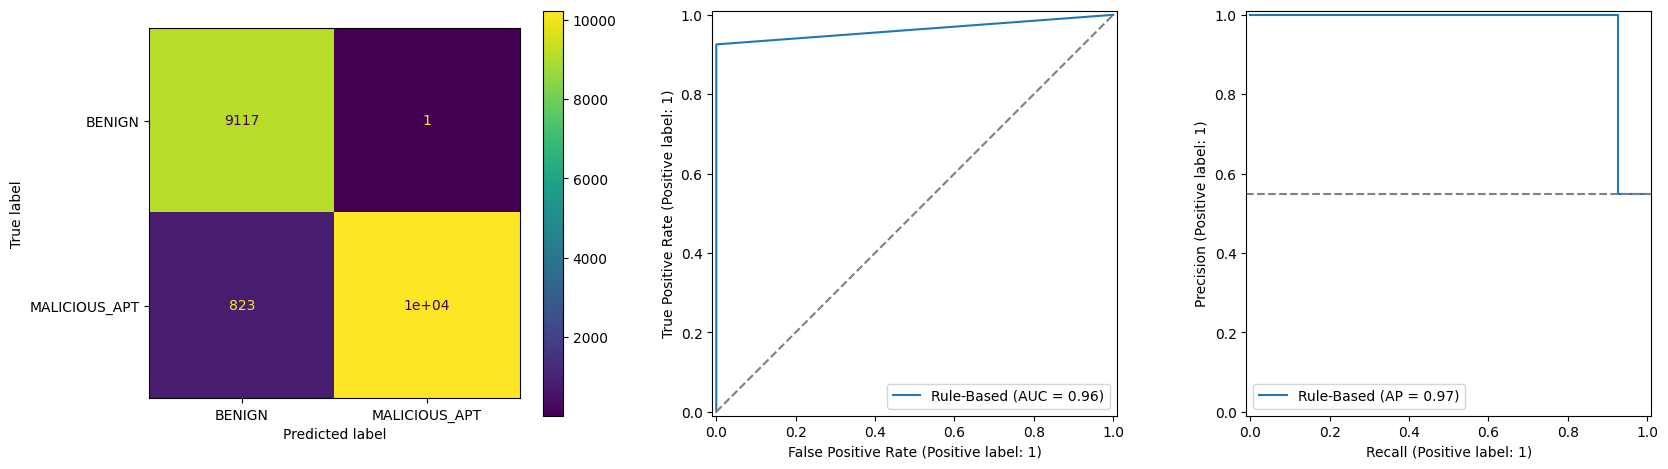

In [10]:
validation_pred=(validation_score>=locked_threshold).astype(int)
validation_result=pd.Series({'accuracy':accuracy_score(y_validation,validation_pred),'precision':precision_score(y_validation,validation_pred,zero_division=0),'recall':recall_score(y_validation,validation_pred,zero_division=0),'f1':f1_score(y_validation,validation_pred,zero_division=0),'f2':fbeta_score(y_validation,validation_pred,beta=2,zero_division=0),'roc_auc':roc_auc_score(y_validation,validation_score),'average_precision':average_precision_score(y_validation,validation_score)})
display(validation_result.to_frame('VALIDATION'))
fig,axes=plt.subplots(1,3,figsize=(17,4.8)); ConfusionMatrixDisplay.from_predictions(y_validation,validation_pred,display_labels=['BENIGN','MALICIOUS_APT'],ax=axes[0]); RocCurveDisplay.from_predictions(y_validation,validation_score,name='Rule-Based',ax=axes[1]); axes[1].plot([0,1],[0,1],'--',color='gray'); PrecisionRecallDisplay.from_predictions(y_validation,validation_score,name='Rule-Based',ax=axes[2]); axes[2].axhline(float(y_validation.mean()),ls='--',color='gray'); plt.tight_layout(); plt.show()

## 9. Đánh giá Test đúng một lần
Dùng nguyên luật và threshold đã khóa trên Validation.

,TEST
accuracy,0.792490
precision,0.999329
recall,0.636030
f1,0.777325
f2,0.685901
roc_auc,0.817741
average_precision,0.842959


{'TN': 8846, 'FP': 5, 'FN': 4261, 'TP': 7446}


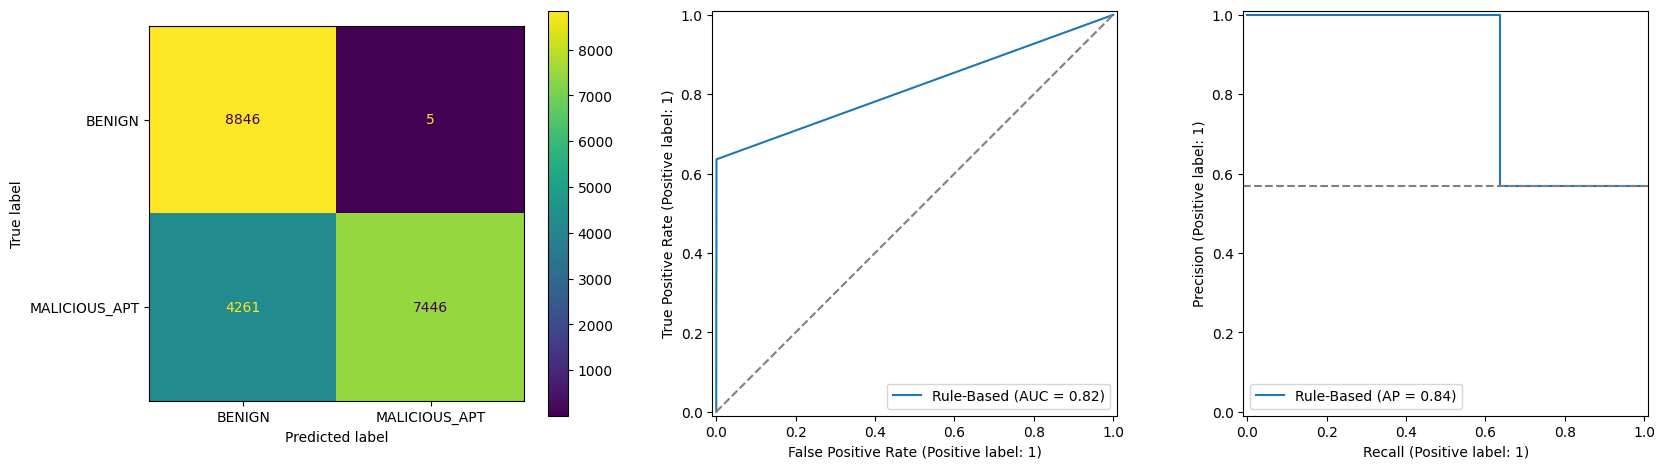

In [11]:
X_test,y_test=test.loc[:,MODEL_FEATURES],test[TARGET_COLUMN]
test_score=rule_score(X_test); test_pred=(test_score>=locked_threshold).astype(int)
test_result=pd.Series({'accuracy':accuracy_score(y_test,test_pred),'precision':precision_score(y_test,test_pred,zero_division=0),'recall':recall_score(y_test,test_pred,zero_division=0),'f1':f1_score(y_test,test_pred,zero_division=0),'f2':fbeta_score(y_test,test_pred,beta=2,zero_division=0),'roc_auc':roc_auc_score(y_test,test_score),'average_precision':average_precision_score(y_test,test_score)})
display(test_result.to_frame('TEST'))
tn,fp,fn,tp=confusion_matrix(y_test,test_pred,labels=[0,1]).ravel(); print({'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)})
fig,axes=plt.subplots(1,3,figsize=(17,4.8)); ConfusionMatrixDisplay.from_predictions(y_test,test_pred,display_labels=['BENIGN','MALICIOUS_APT'],ax=axes[0]); RocCurveDisplay.from_predictions(y_test,test_score,name='Rule-Based',ax=axes[1]); axes[1].plot([0,1],[0,1],'--',color='gray'); PrecisionRecallDisplay.from_predictions(y_test,test_score,name='Rule-Based',ax=axes[2]); axes[2].axhline(float(y_test.mean()),ls='--',color='gray'); plt.tight_layout(); plt.show()

## 10. Khoảng bất định bằng bootstrap
Bootstrap theo từng dòng Test chỉ mô tả độ dao động nội bộ, không chọn lại luật/ngưỡng.

In [12]:
rng=np.random.default_rng(SEED); boot=[]; y_array=y_test.to_numpy()
for _ in range(300):
    idx=rng.integers(0,len(y_array),len(y_array))
    if np.unique(y_array[idx]).size<2: continue
    boot.append({'f2':fbeta_score(y_array[idx],test_pred[idx],beta=2,zero_division=0),'roc_auc':roc_auc_score(y_array[idx],test_score[idx]),'average_precision':average_precision_score(y_array[idx],test_score[idx])})
boot=pd.DataFrame(boot)
display(pd.DataFrame({'estimate':test_result[['f2','roc_auc','average_precision']],'ci_2.5%':boot.quantile(.025),'ci_97.5%':boot.quantile(.975)}))

,estimate,ci_2.5%,ci_97.5%
f2,0.685901,0.678742,0.694417
roc_auc,0.817741,0.813920,0.822277
average_precision,0.842959,0.838689,0.847757


## 11. Lưu kết quả thực nghiệm
Rule-Based không có model `.joblib`; lưu định nghĩa luật, threshold, split hash và metric vào JSON.

In [13]:
experiment_dir=ROOT/'reports'/'notebook_experiments'; experiment_dir.mkdir(parents=True,exist_ok=True)
record={'schema_version':2,'model':'rule_based','rule_weights':dict(rule_weights.values.tolist()),'locked_threshold':locked_threshold,'split_hash':split_hash,'validation_locked_threshold':{k:float(v) for k,v in validation_result.items()},'test_locked_threshold':{k:float(v) for k,v in test_result.items()}}
(experiment_dir/'03_rule_based.json').write_text(json.dumps(record,indent=2),encoding='utf-8'); record

{'schema_version': 2,
 'model': 'rule_based',
 'rule_weights': {'has_command_line': 2,
  'has_parent_command_line': 1,
  'has_hashes': 2,
  'has_target_file': 1,
  'has_source_ip': 1,
  'event_status failure/failed/denied': 1},
 'locked_threshold': 1,
 'split_hash': 'a94bf5446c1c1c5dfd396f631915ee856feabe56a8892eb656b3c234ee7239a8',
 'validation_locked_threshold': {'accuracy': 0.9591593973037272,
  'precision': 0.9999023055881203,
  'recall': 0.9255742448905769,
  'f1': 0.961303653611346,
  'f2': 0.9395424836601307,
  'roc_auc': 0.962729702220968,
  'average_precision': 0.9663127627009522},
 'test_locked_threshold': {'accuracy': 0.7924895417842203,
  'precision': 0.9993289491343443,
  'recall': 0.6360297258050739,
  'f1': 0.7773253993109928,
  'f2': 0.6859006245509313,
  'roc_auc': 0.8177412297478436,
  'average_precision': 0.8429588097968732}}

## 12. Kết luận và giới hạn
Rule-Based là baseline giải thích được nhưng độ bao phủ thấp và không tự thích nghi. Chỉ dùng để chứng minh mô hình học máy có cải thiện thực sự; không trình bày đây là mô hình AI hoặc thay thế Wazuh.

## Cập nhật pipeline dữ liệu hợp nhất

Notebook này thuộc bộ thí nghiệm SecuraAI mới. Có hai tầng kết quả cần phân biệt:

- **Thí nghiệm giảng dạy 00–10:** so sánh thuật toán trên cùng split Windows-APT để bảo đảm công bằng.
- **Baseline hợp nhất theo từng event:** Windows-APT 2025 + RADAR + log Wazuh đã bộc lộ domain shift khi test trực tiếp.
- **Ứng viên temporal:** dùng `event_family`, `event_type` và thống kê cửa sổ 5 phút; vẫn chỉ chạy shadow.

RADAR bổ sung ground truth ransomware/Sysmon theo từng mẫu thực thi. Log Wazuh hiện tại chỉ là kiểm thử lab và weak-benign; không được trình bày như bằng chứng production. Test, threshold và dữ liệu ngoài miền được giữ tách biệt để giảm leakage.

In [14]:
import pandas as pd

combined_artifact_dir = ROOT / 'artifacts-combined-candidate'
combined_metadata_path = combined_artifact_dir / 'model_metadata.json'
combined_source_report_path = ROOT / 'reports' / 'combined_candidate_by_source.json'
temporal_artifact_dir = ROOT / 'artifacts-temporal-candidate'
temporal_metadata_path = temporal_artifact_dir / 'model_metadata.json'

if combined_metadata_path.exists():
    combined_metadata = json.loads(combined_metadata_path.read_text(encoding='utf-8'))
    display(pd.DataFrame({
        'value': [
            combined_metadata['selectedModel'],
            combined_metadata['lockedThreshold'],
            ', '.join(combined_metadata['datasets']),
            combined_metadata['test']['f2'],
            combined_metadata['test']['precision'],
            combined_metadata['test']['recall'],
        ]
    }, index=['selected_model','locked_threshold','datasets','combined_test_f2','combined_test_precision','combined_test_recall']))
else:
    print('Chưa có artifacts-combined-candidate. Chạy scripts/train_combined_candidate.py trước.')

if temporal_metadata_path.exists():
    temporal_metadata = json.loads(temporal_metadata_path.read_text(encoding='utf-8'))
    display(pd.DataFrame({
        'value': [
            temporal_metadata['selectedModel'], temporal_metadata['lockedThreshold'],
            temporal_metadata['validation']['f2'], temporal_metadata['test']['f2'],
            temporal_metadata['test']['falsePositiveRate'], temporal_metadata['status'],
        ]
    }, index=['temporal_model','temporal_threshold','validation_f2','test_f2','test_fpr','status']))
else:
    print('Chưa có artifacts-temporal-candidate. Chạy scripts/train_temporal_candidate.py trước.')


,value
selected_model,logistic_regression
locked_threshold,0.442104
datasets,"Windows-APT 2025 v4, RADAR v0.0.1-beta"
combined_test_f2,0.994966
combined_test_precision,0.990039
combined_test_recall,0.996205


,value
temporal_model,random_forest
temporal_threshold,0.735188
validation_f2,0.866388
test_f2,0.882957
test_fpr,0.039261
status,EXPERIMENTAL_SYNTHETIC_ONLY
